In [1]:
import numpy as np
import ramanspy as rp
import matplotlib.pyplot as plt
import os

In [2]:
dir_ = os.path.join(os.getcwd(), "data")

X_train_sc, y_train = rp.datasets.bacteria("train", folder=dir_)
X_val_sc,   y_val   = rp.datasets.bacteria("val", folder=dir_)
X_test_sc,  y_test  = rp.datasets.bacteria("test", folder=dir_)

In [3]:
# Labels for class names
y_labels, antibiotics_labels = rp.datasets.bacteria("labels")
print(y_labels)

['C. albicans', 'C. glabrata', 'K. aerogenes', 'E. coli 1', 'E. coli 2', 'E. faecium', 'E. faecalis 1', 'E. faecalis 2', 'E. cloacae', 'K. pneumoniae 1', 'K. pneumoniae 2', 'P. mirabilis', 'P. aeruginosa 1', 'P. aeruginosa 2', 'MSSA 1', 'MSSA 3', 'MRSA 1 (isogenic)', 'MRSA 2', 'MSSA 2', 'S. enterica', 'S. epidermidis', 'S. lugdunensis', 'S. marcescens', 'S. pneumoniae 2', 'S. pneumoniae 1', 'S. sanguinis', 'Group A Strep.', 'Group B Strep.', 'Group C Strep.', 'Group G Strep.']


In [5]:
spectra = [X_val_sc[y_val == species_id] for species_id in list(np.unique(y_val))]

In [6]:
spectra_ = rp.preprocessing.normalise.MinMax().apply(spectra)

<Axes: xlabel='Raman shift (cm$^{{{-1}}}$)', ylabel='Intensity (a.u.)'>

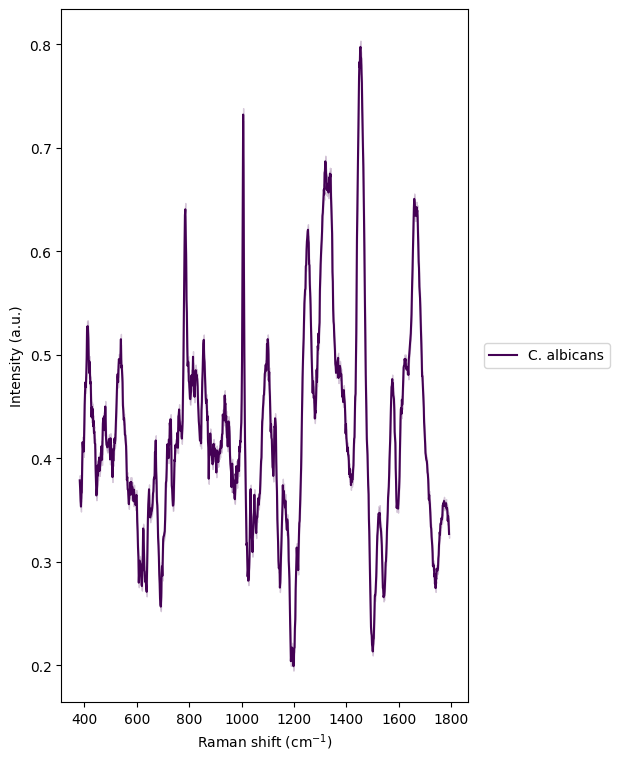

In [7]:
plt.figure(figsize=(6.5, 9))
rp.plot.mean_spectra(spectra_, label=y_labels, plot_type="single stacked", title=None)

In [ ]:
# Extract spectral data (NumPy arrays)
X_train = X_train_sc.spectral_data
X_val   = X_val_sc.spectral_data
X_test  = X_test_sc.spectral_data

print("Original shapes:")
print("Train:", X_train.shape, "Val:", X_val.shape, "Test:", X_test.shape)



print(f"Shape of single spectrum: {X_train[0].shape}")
print(f"First 10 values: {X_train[0][:10]}")


Original shapes:
Train: (60000, 1000) Val: (3000, 1000) Test: (3000, 1000)
Shape of single spectrum: (1000,)
First 10 values: [0.24007765 0.14707421 0.25676307 0.2653013  0.15018849 0.24619648
 0.2804535  0.25856074 0.20867327 0.26299443]


In [13]:
help(rp.datasets.bacteria)


Help on function bacteria in module ramanspy.datasets:

bacteria(dataset='train', folder=None) -> Tuple[ramanspy.core.SpectralContainer, numpy.ndarray]
    Raman spectra acquired from different bacterial and yeast isolates.

    >80k spectra across 30+ isolates. Ideal for classification modelling.

    Data from `Ho, CS. et al. (2019) <https://www.nature.com/articles/s41467-019-12898-9>`_.

    Must be downloaded first. Provided by authors on `DropBox <https://www.dropbox.com/sh/gmgduvzyl5tken6/AABtSWXWPjoUBkKyC2e7Ag6Da?dl=0>`_.

    Parameters
    ----------
    dataset : str, default='train'
        Which bacteria dataset to load.

        Available datasets are:

        - ``'train'`` - 60k spectra, 2k for each of 30 different reference bacterial and yeast isolates;
        - ``'val'`` - 3k spectra, 100 spectra for each of the reference isolates;
        - ``'test'`` - 3k spectra, 100 spectra for each of the reference isolates;
        - ``'clinical2018'`` - 12k spectra, 400 spectra